
Builds a dataframe where each sample keeps its row/column structure as inputs.
No mean/std/min/max or sum based feature engineering is used.

In [14]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [3]:
label_name_map = {
    -1: "noise",
    1: "ceiling shot",
    2: "power shot",
    3: "waving dash",
    5: "air dribble",
    6: "front flick",
    7: "musty flick",
}
valid_labels = set(label_name_map.keys())

In [4]:
def parse_skillshots_data(file_path: Path):
    lines = [
        ln.strip()
        for ln in file_path.read_text(encoding="utf-8", errors="replace").splitlines()
        if ln.strip()
    ]
    if not lines:
        raise ValueError("Input file is empty.")

    feature_names = lines[0].split()
    if len(feature_names) != 18:
        raise ValueError("Expected 18 feature names in header.")

    X_sequences = []
    y_labels = []

    current_label = None
    current_rows = []

    def flush_current_sample():
        if current_label is None or len(current_rows) == 0:
            return
        seq_df = pd.DataFrame(current_rows, columns=feature_names)
        X_sequences.append(seq_df)
        y_labels.append(current_label)

    for line_num, line in enumerate(lines[1:], start=2):
        tokens = line.split()

        if len(tokens) == 1:
            try:
                maybe_label = int(tokens[0])
            except ValueError:
                maybe_label = None

            if maybe_label in valid_labels:
                flush_current_sample()
                current_label = maybe_label
                current_rows = []
                continue

            raise ValueError(
                f"Line {line_num}: single-token line '{tokens[0]}' is not a valid label."
            )

        if len(tokens) != 18:
            raise ValueError(
                f"Line {line_num}: expected 18 numeric values or a single label. Got {len(tokens)} token(s)."
            )

        try:
            row_values = [float(tok) for tok in tokens]
        except ValueError as exc:
            raise ValueError(f"Line {line_num}: non-numeric value found in feature row.") from exc

        current_rows.append(row_values)

    flush_current_sample()
    return feature_names, X_sequences, y_labels

In [5]:
def sequence_to_fixed_matrix(seq_df: pd.DataFrame, feature_names: list[str], expected_rows: int = 18):
    values = seq_df[feature_names].to_numpy(dtype=float)
    n_rows, n_cols = values.shape

    if n_cols != len(feature_names):
        raise ValueError("Feature column mismatch while building matrix.")

    if n_rows == expected_rows:
        return values

    if n_rows > expected_rows:
        return values[:expected_rows, :]

    pad = np.zeros((expected_rows - n_rows, n_cols), dtype=float)
    return np.vstack([values, pad])

In [6]:
def build_rowcol_dataframe(X_sequences, y_labels, feature_names, expected_rows: int = 18):
    flat_feature_names = [
        f"t{t:02d}_{col}"
        for t in range(expected_rows)
        for col in feature_names
    ]

    rows = []
    for seq_df, label in zip(X_sequences, y_labels):
        matrix = sequence_to_fixed_matrix(seq_df, feature_names, expected_rows=expected_rows)
        flat = matrix.reshape(-1)

        row = {name: float(val) for name, val in zip(flat_feature_names, flat)}
        row["label"] = int(label)
        row["class_name"] = label_name_map[int(label)]
        rows.append(row)

    df = pd.DataFrame(rows)

    sorted_labels = sorted(valid_labels)
    label_to_index = {lab: idx for idx, lab in enumerate(sorted_labels)}
    index_to_label = {idx: lab for lab, idx in label_to_index.items()}
    index_to_name = {idx: label_name_map[lab] for idx, lab in index_to_label.items()}

    df["target"] = df["label"].map(label_to_index)
    return df, label_to_index, index_to_label, index_to_name

In [8]:
data_path = Path("data/rocket_league_skillshots.data")
feature_names, X_sequences, y_labels = parse_skillshots_data(data_path)

# Set expected_rows to 18 to match your current assumption of 18 lines per sample.
df, label_to_index, index_to_label, index_to_name = build_rowcol_dataframe(
    X_sequences,
    y_labels,
    feature_names,
    expected_rows=18,
)

print("DataFrame created without aggregation.")
print("Number of samples:", len(df))
print("Number of columns:", df.shape[1])
display(df.head())
df.info()

DataFrame created without aggregation.
Number of samples: 298
Number of columns: 327


,t00_BallAcceleration,t00_Time,t00_DistanceWall,t00_DistanceCeil,t00_DistanceBall,t00_PlayerSpeed,t00_BallSpeed,t00_up,t00_accelerate,t00_slow,...,t17_left,t17_boost,t17_camera,t17_down,t17_right,t17_slide,t17_jump,label,class_name,target
0,1636.798772,0.0,3498.01,2012.98,299.668270,104267.426232,99035.849338,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,1.0,1.0,6,front flick,5
1,0.000000,0.0,39.78,1704.50,193.421147,141332.104937,33685.839532,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,-1,noise,0
2,124246.293754,0.0,35.49,1450.25,230.480541,145691.810607,171036.828844,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,-1,noise,0
3,-8210.634012,0.0,36.00,1036.28,579.439757,133427.214278,143370.859169,0.0,0.0,0.0,...,0.0,1.0,1.0,0.0,1.0,0.0,1.0,-1,noise,0
4,1197.536062,0.0,3975.02,2013.04,142.937646,114474.612924,123766.715320,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,-1,noise,0


<class 'pandas.DataFrame'>
RangeIndex: 298 entries, 0 to 297
Columns: 327 entries, t00_BallAcceleration to target
dtypes: float64(324), int64(2), str(1)
memory usage: 761.4 KB


In [12]:
df.isnull().sum()

t00_BallAcceleration    0
t00_Time                0
t00_DistanceWall        0
t00_DistanceCeil        0
t00_DistanceBall        0
                       ..
t17_slide               0
t17_jump                0
label                   0
class_name              0
target                  0
Length: 327, dtype: int64

DataFrame shape: (298, 327)

Class counts:
label
-1    43
 1    30
 2    60
 3    38
 5    45
 6    46
 7    36
Name: count, dtype: int64


C:\Users\Ethan Bennett\AppData\Local\Temp\ipykernel_14244\1033916705.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(


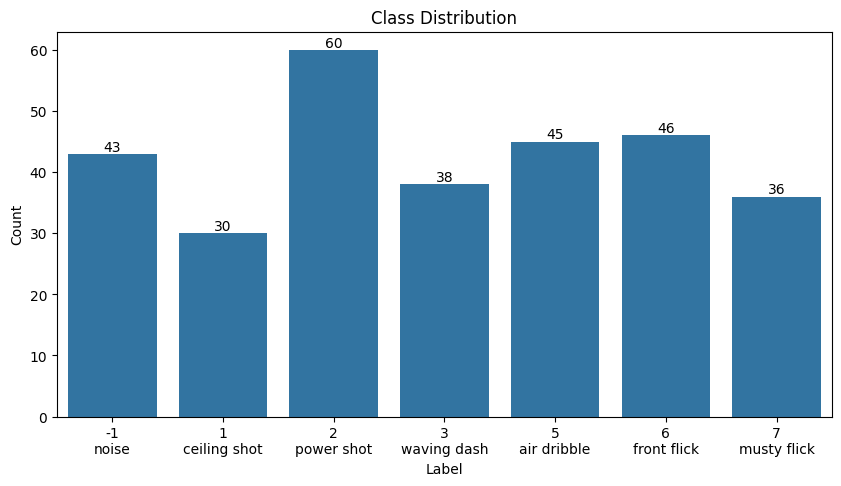

In [15]:
print("DataFrame shape:", df.shape)
print("\nClass counts:")
print(df["label"].value_counts().sort_index())

plt.figure(figsize=(10, 5))
order = sorted(df["label"].unique())
ax = sns.countplot(data=df, x="label", order=order)
ax.set_xticklabels(
    [f"{label}\n{label_name_map.get(label, 'unknown')}" for label in order]
)
for p in ax.patches:
    height = p.get_height()
    ax.annotate(
        f"{int(height)}",
        (p.get_x() + p.get_width() / 2, height),
        ha="center",
        va="bottom",
        fontsize=10
    )
plt.title("Class Distribution")
plt.xlabel("Label")
plt.ylabel("Count")
plt.show()

In [26]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
exclude_cols = ["label", "target"]
numeric_feature_cols = [c for c in numeric_cols if c not in exclude_cols]

X = df[numeric_feature_cols].values
y = df["target"].values

#Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y)

#Scale data
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


#Convert to tensors (ensure dtypes match model parameters)
X_train = torch.tensor(X_train_scaled, dtype=torch.float32)
X_test = torch.tensor(X_test_scaled, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

print("Train X shape:", X_train.shape)
print("Test X shape:", X_test.shape)

Train X shape: torch.Size([223, 324])
Test X shape: torch.Size([75, 324])


In [38]:
from torch.utils.data import TensorDataset, DataLoader

batch_size = 32

train_dataset = TensorDataset(X_train, y_train)
test_dataset = TensorDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

In [28]:
import torch.nn as nn

class LinearClassificationModel(nn.Module):

    def __init__(self, input_features, output_classes, sigma=0.01):

        super(LinearClassificationModel, self).__init__()

        self.net = nn.Sequential(                           
            nn.Linear(input_features, output_classes)   
        )

        nn.init.normal_(self.net[0].weight, mean=0, std=sigma)
        nn.init.zeros_(self.net[0].bias)

    def forward(self, X):
        return self.net(X)

In [29]:
class CrossEntropyLossWrapper:

    def __init__(self):

        self.criterion = nn.CrossEntropyLoss()
    
    def __call__(self, predictions, targets):
        
        return self.criterion(predictions, targets)

In [30]:
class SGDOptimizer:

    def __init__(self, model_params, lr=0.01):

        self.optimizer = torch.optim.SGD(model_params, lr=lr)
    
    def zero_grad(self):

        self.optimizer.zero_grad()
    
    def step(self):
        
        self.optimizer.step()




class AdamOptimizer:

    def __init__(self, model_params, lr=0.01):

        self.optimizer = torch.optim.Adam(model_params, lr=lr)
    
    def zero_grad(self):

        self.optimizer.zero_grad()
    
    def step(self):
        
        self.optimizer.step()

In [ ]:
input_size = 324
num_classes = 7

lr = 0.01

model = LinearClassificationModel(input_size, num_classes)
lossfn = CrossEntropyLossWrapper()
optimizer = AdamOptimizer(model.parameters(), lr=lr)

epochs = 10
total_epoch_loss = []
final_accuracy   = []

model.train()

for epoch in range(epochs):

    total_loss = 0.0
    correct    = 0
    total      = 0

    for idx, (batchX, batchy) in enumerate(train_loader):
        
        optimizer.zero_grad()
        y_hat = model(batchX)            
        loss = lossfn(y_hat, batchy) 
        loss.backward()                    
        optimizer.step() 

        predicted = torch.argmax(y_hat, dim=1)
        correct += (predicted == batchy).sum().item()
        total += batchy.size(0)
        total_loss += loss.item()

    epoch_loss = total_loss / len(train_loader)
    epoch_accuracy = 100.0 * correct / total

    total_epoch_loss.append(epoch_loss)
    final_accuracy.append(epoch_accuracy)

    print(f"Epoch [{epoch+1}/{epochs}] | Loss: {epoch_loss:.4f} | Accuracy: {epoch_accuracy:.2f}%")

# Plot training accuracy per epoch
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 4))
plt.plot(list(range(1, epochs+1)), final_accuracy, marker='o')
plt.title('Training Accuracy per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.grid(True)
plt.show()


Epoch [1/10] | Loss: 1.6995 | Accuracy: 43.95%
Epoch [2/10] | Loss: 0.6961 | Accuracy: 78.92%
Epoch [3/10] | Loss: 0.3734 | Accuracy: 89.24%
Epoch [4/10] | Loss: 0.2228 | Accuracy: 95.96%
Epoch [5/10] | Loss: 0.1513 | Accuracy: 98.21%
Epoch [6/10] | Loss: 0.1111 | Accuracy: 99.55%
Epoch [7/10] | Loss: 0.0828 | Accuracy: 100.00%
Epoch [8/10] | Loss: 0.0665 | Accuracy: 100.00%
Epoch [9/10] | Loss: 0.0554 | Accuracy: 100.00%
Epoch [10/10] | Loss: 0.0467 | Accuracy: 100.00%


In [56]:
model.eval()

correct = 0
total   = 0

with torch.no_grad():
    for batchX, batchy in test_loader:

        outputs   = model(batchX)                    
        predicted = torch.argmax(outputs, dim=1)     

        correct += (predicted == batchy).sum().item()
        total   += batchy.size(0)

test_accuracy = 100 * correct / total
print(f"\nTest accuracy: {test_accuracy:.2f}%")


Test accuracy: 53.33%
